In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = "/content/drive/MyDrive/credit-risk"
sys.path.insert(0, f"{PROJECT_ROOT}/src")

df = pd.read_csv(f"{PROJECT_ROOT}/data/processed/df_features.csv")

print(f"✅ Loaded: {df.shape}")
print(f"   Nulls: {df.isnull().sum().sum()}")
print(f"   Columns: {list(df.columns)}")

✅ Loaded: (150000, 21)
   Nulls: 0
   Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'income_missing', 'DebtToIncomeRatio', 'IncomePerDependent', 'TotalLatePayments', 'LatePaymentRatio', 'UtilizationBin', 'AgeGroup', 'log_MonthlyIncome', 'log_DebtRatio', 'log_RevolvingUtilizationOfUnsecuredLines']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from xgboost import XGBClassifier
import shap
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("✅ All libraries ready")

✅ All libraries ready


In [5]:
# Drop categorical columns — SHAP/VIF work on numeric features only
# We'll handle UtilizationBin and AgeGroup as categoricals in Phase 5
drop_cols = ["UtilizationBin", "AgeGroup"]
target = "SeriousDlqin2yrs"

X = df.drop(columns=[target] + drop_cols)
y = df[target]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")

# Train a lightweight XGBoost — just enough for SHAP, not the final model
model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=(y == 0).sum() / (y == 1).sum(),  # handles imbalance
    random_state=42,
    eval_metric="logloss"
)
model.fit(X, y)
print("\n✅ Model trained")

Features shape: (150000, 18)
Target distribution:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

✅ Model trained


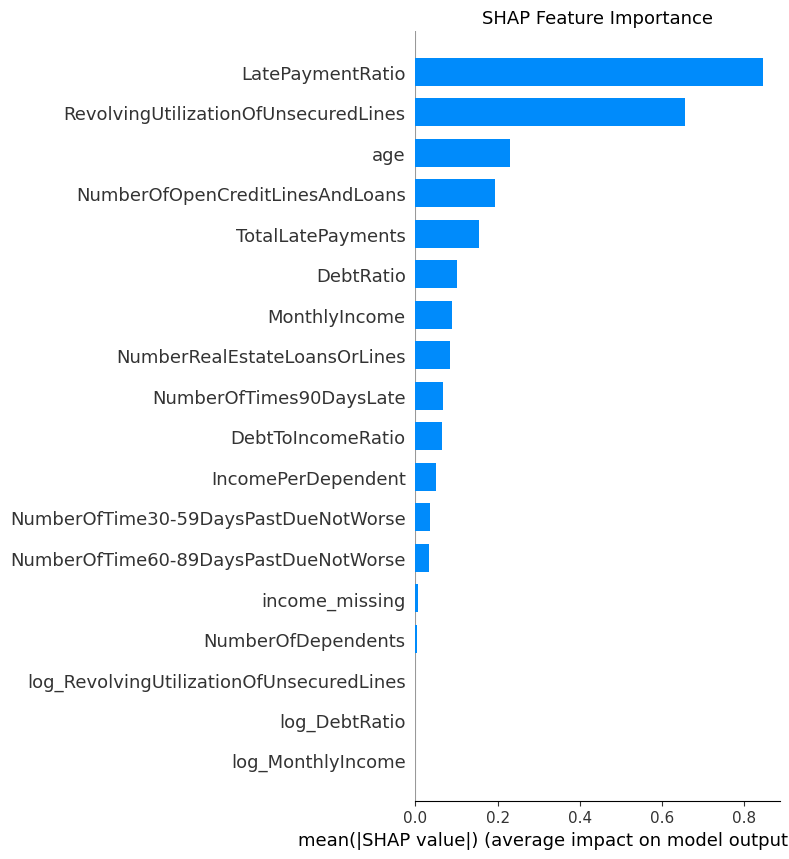

✅ Saved to reports/figures/shap_importance.png


In [6]:
# Compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# Plot — this is the money chart
plt.figure()
shap.summary_plot(
    shap_values, X,
    plot_type="bar",
    show=False
)
plt.title("SHAP Feature Importance", fontsize=13)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/reports/figures/shap_importance.png", dpi=150)
plt.show()

print("✅ Saved to reports/figures/shap_importance.png")

In [7]:
shap_importance = pd.DataFrame({
    "feature": X.columns,
    "shap_importance": np.abs(shap_values).mean(axis=0)
}).sort_values("shap_importance", ascending=False)

print(shap_importance.to_string(index=False))

                                 feature  shap_importance
                        LatePaymentRatio         0.845331
    RevolvingUtilizationOfUnsecuredLines         0.656240
                                     age         0.230324
         NumberOfOpenCreditLinesAndLoans         0.193251
                       TotalLatePayments         0.155746
                               DebtRatio         0.101203
                           MonthlyIncome         0.089185
            NumberRealEstateLoansOrLines         0.084944
                 NumberOfTimes90DaysLate         0.067331
                       DebtToIncomeRatio         0.065096
                      IncomePerDependent         0.049948
    NumberOfTime30-59DaysPastDueNotWorse         0.036591
    NumberOfTime60-89DaysPastDueNotWorse         0.032836
                          income_missing         0.005905
                      NumberOfDependents         0.004328
                       log_MonthlyIncome         0.000000
              

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF only on features we're considering keeping
log_cols = ["log_MonthlyIncome", "log_DebtRatio", "log_RevolvingUtilizationOfUnsecuredLines"]
X_vif = X.drop(columns=log_cols)

vif_data = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values("VIF", ascending=False)

print(vif_data.to_string(index=False))

                             feature        VIF
NumberOfTime30-59DaysPastDueNotWorse        inf
             NumberOfTimes90DaysLate        inf
NumberOfTime60-89DaysPastDueNotWorse        inf
                   TotalLatePayments        inf
                    LatePaymentRatio 182.300216
                       MonthlyIncome  16.420124
                  IncomePerDependent  15.002646
                                 age   6.253532
     NumberOfOpenCreditLinesAndLoans   4.796234
                  NumberOfDependents   3.832353
                      income_missing   2.631642
        NumberRealEstateLoansOrLines   2.586729
                           DebtRatio   2.460455
RevolvingUtilizationOfUnsecuredLines   1.785847
                   DebtToIncomeRatio   1.140729


In [9]:
# Features to drop based on SHAP + VIF analysis
drop_shap_zero = [
    "log_MonthlyIncome", "log_DebtRatio",
    "log_RevolvingUtilizationOfUnsecuredLines"
]

drop_vif = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "MonthlyIncome"  # IncomePerDependent captures this better
]

# These go to Phase 6 meta-learner only, not tree models
log_features = df[drop_shap_zero + [target]]

# Final feature set for tree models
final_features = X.drop(columns=drop_shap_zero + drop_vif)

print(f"Features before selection: {X.shape[1]}")
print(f"Features after selection:  {final_features.shape[1]}")
print(f"\nFinal features:\n{list(final_features.columns)}")
print(f"\nLog features saved for meta-learner:\n{list(log_features.columns)}")

Features before selection: 18
Features after selection:  11

Final features:
['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines', 'NumberOfDependents', 'income_missing', 'DebtToIncomeRatio', 'IncomePerDependent', 'TotalLatePayments', 'LatePaymentRatio']

Log features saved for meta-learner:
['log_MonthlyIncome', 'log_DebtRatio', 'log_RevolvingUtilizationOfUnsecuredLines', 'SeriousDlqin2yrs']


In [10]:
# Save final feature set for tree models
final_df = pd.concat([final_features, y], axis=1)
final_df.to_csv(f"{PROJECT_ROOT}/data/processed/df_selected.csv", index=False)
print(f"✅ Tree model dataset saved: {final_df.shape}")

# Save log features for meta-learner
log_features.to_csv(f"{PROJECT_ROOT}/data/processed/df_log_features.csv", index=False)
print(f"✅ Meta-learner dataset saved: {log_features.shape}")

✅ Tree model dataset saved: (150000, 12)
✅ Meta-learner dataset saved: (150000, 4)


## Feature Selection — Summary

Started with 18 numeric features. Ended with 11. Every cut was justified.

**SHAP analysis** revealed that LatePaymentRatio (our engineered feature) is the
single most important predictor — SHAP importance 0.845, higher than any original
column. The three log-transformed features scored zero with tree models and were
moved to a separate file for the logistic regression meta-learner in Phase 6.

**VIF analysis** caught perfect multicollinearity: the three individual late payment
columns were infinitely collinear with TotalLatePayments (their sum). Dropped all
three — TotalLatePayments retains the information. MonthlyIncome was dropped in
favour of IncomePerDependent which encodes the same signal more meaningfully.

**Final feature set (11):** clean, justified, zero redundancy.